<a href="https://colab.research.google.com/github/LuisTT0903/Processamento-de-Sinais1/blob/main/Aula_08/Pratica8Quest%C3%A3o3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

fs = 8192 Hz | N = 73113 amostras | duração = 8.92 s
Potência de x: 0.03851 | interferência 100 Hz: 0.00125 | interferência 2 kHz: 0.00281
sigma^2 = 0.01  SNR de entrada =   4.35 dB
sigma^2 = 0.1   SNR de entrada =  -4.33 dB
sigma^2 = 1.0   SNR de entrada = -14.18 dB

Atraso do sistema: 400 amostras = 48.8 ms (constante em todas as frequências)

(a) Filtros projetados — ganhos em frequências de interesse


,100 Hz (dB),150 Hz (dB),300 Hz (dB),1000 Hz (dB),1850 Hz (dB),2000 Hz (dB),3000 Hz (dB)
Passa-altas 150 Hz (M = 600),-81.5,-6.0,-0.0,0.0,-0.0,0.0,-0.0
Passa-baixas 1850 Hz (M = 200),-0.0,-0.0,0.0,-0.0,-6.0,-81.6,-121.9
Sistema completo (M = 800),-81.5,-6.0,-0.0,-0.0,-6.0,-81.6,-121.9


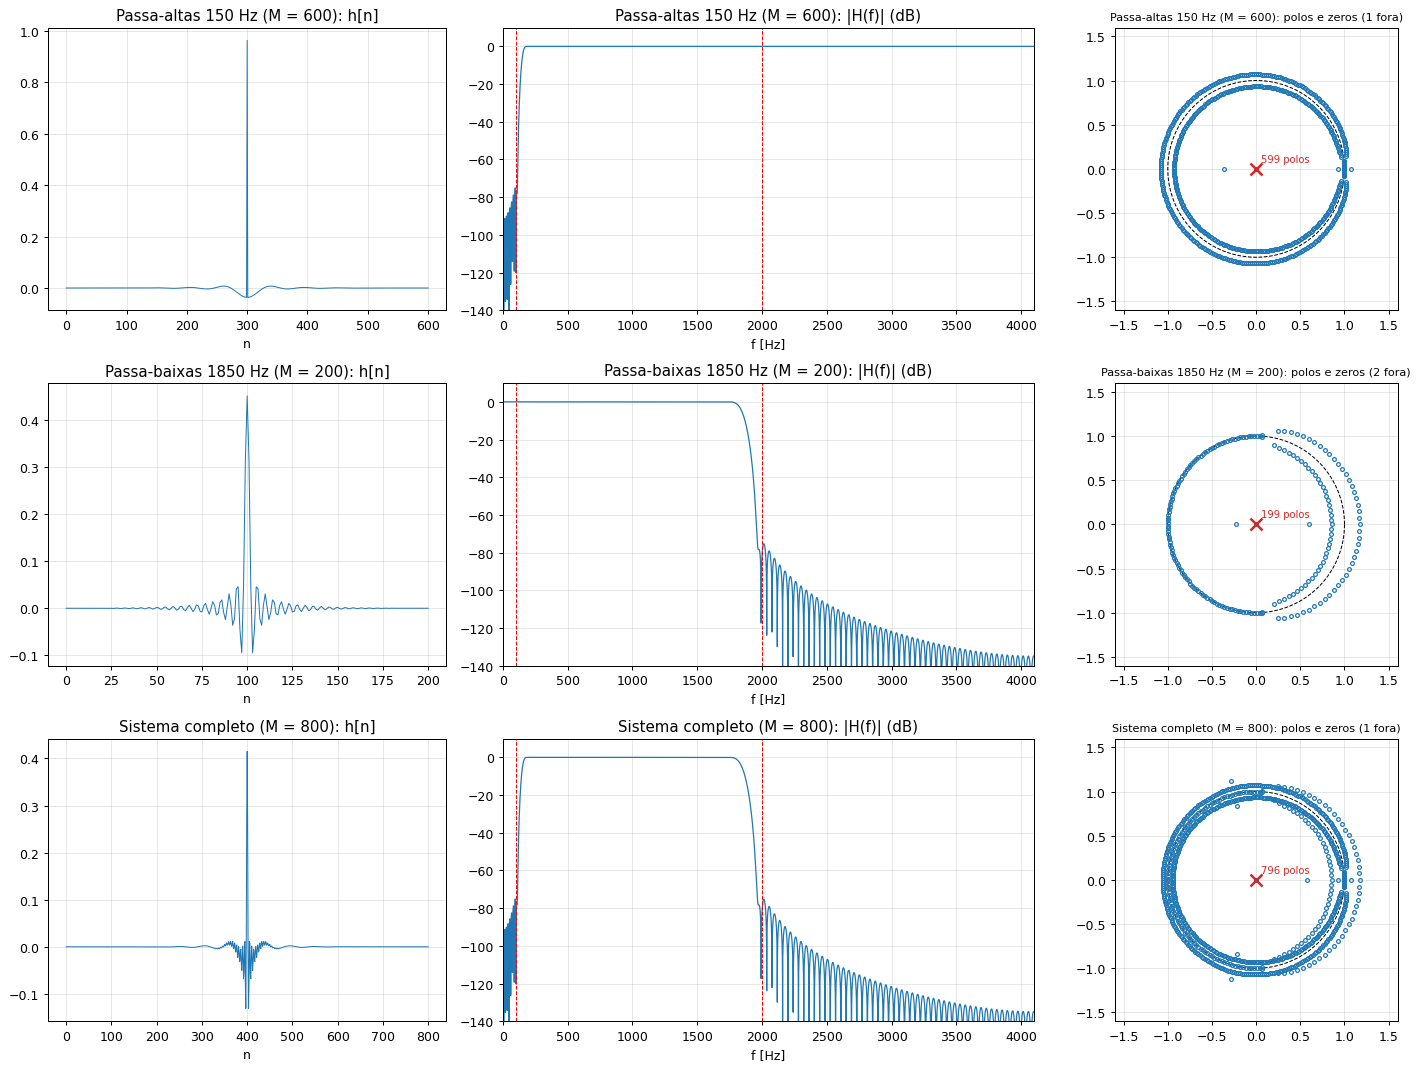

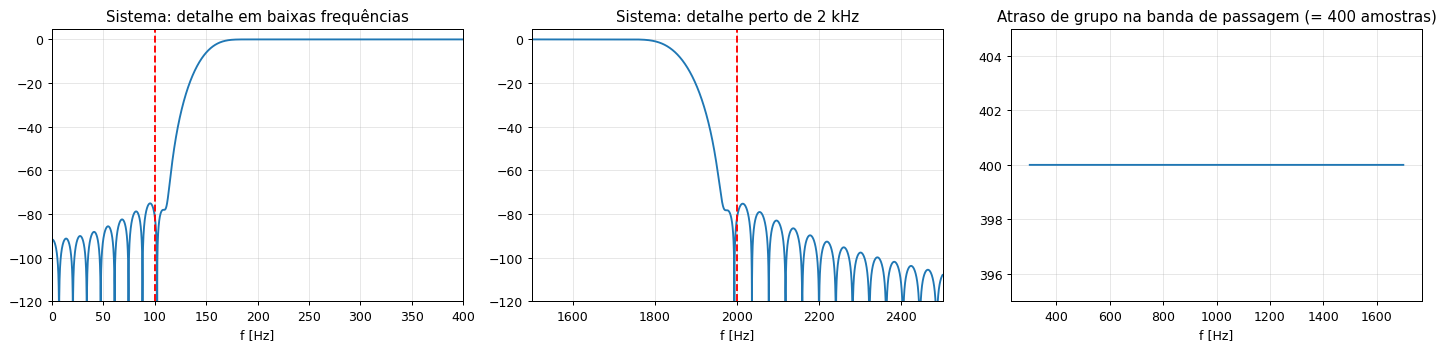


Escolha da janela (σ² = 0,01, M_PA = 600, M_PB = 200):


,|H| 100 Hz (dB),|H| 2 kHz (dB),Interf. residual (dB rel. entrada),SNR saída (dB)
Retangular,-36.8,-38.1,-37.6,8.00
Hann,-71.3,-71.5,-71.4,8.05
Hamming,-60.8,-62.5,-61.9,8.04
Blackman,-81.5,-81.6,-81.6,8.06


Escolha da ordem do passa-altas (Blackman, σ² = 0,01):


,|H| 100 Hz (dB),SNR saída (dB),Atraso (ms)
M_PA,,,
100,-11.7,8.10,18.3
200,-20.6,8.09,24.4
400,-57.1,8.07,36.6
600,-81.5,8.06,48.8
800,-79.8,8.05,61.0
1200,-91.7,8.05,85.4


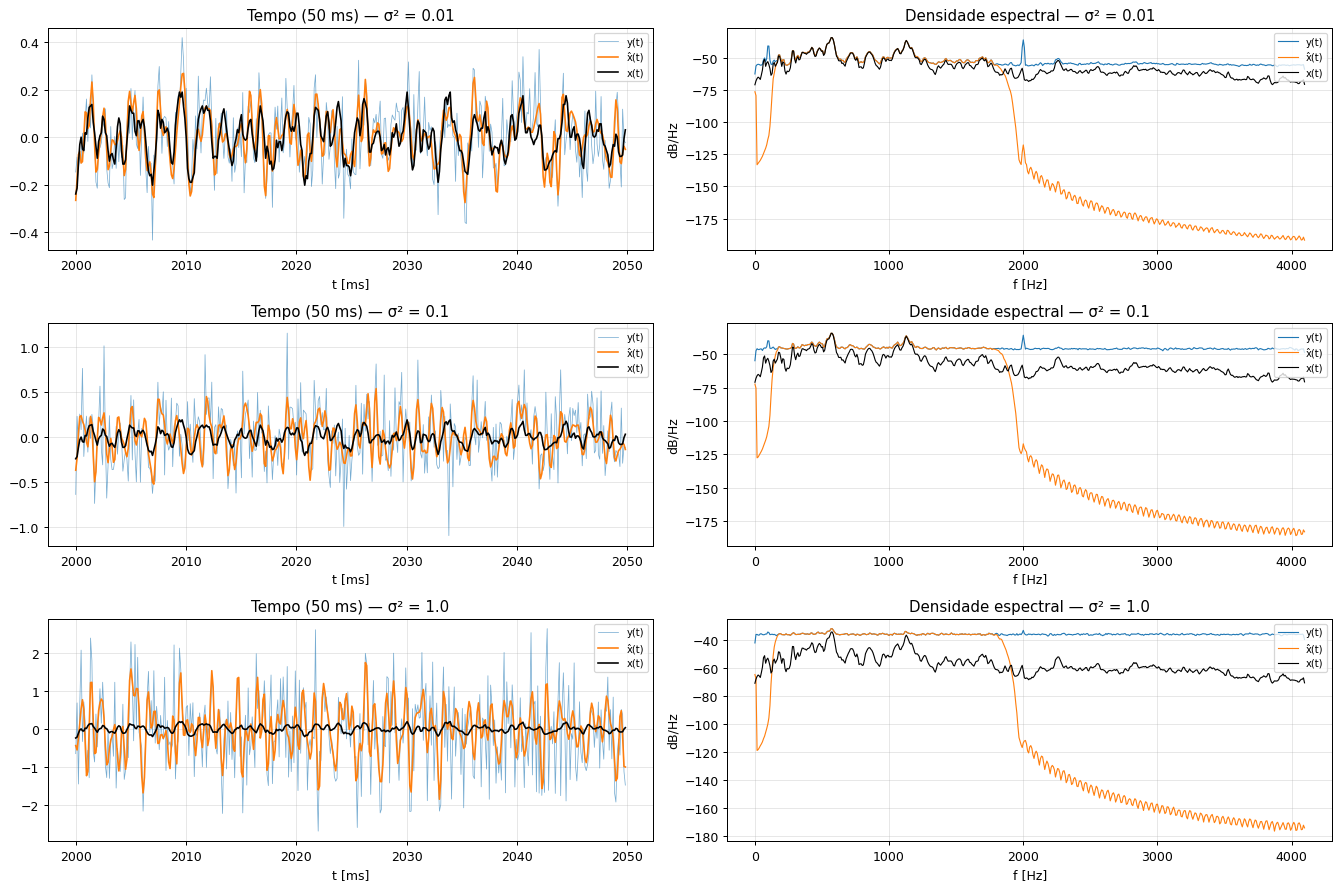

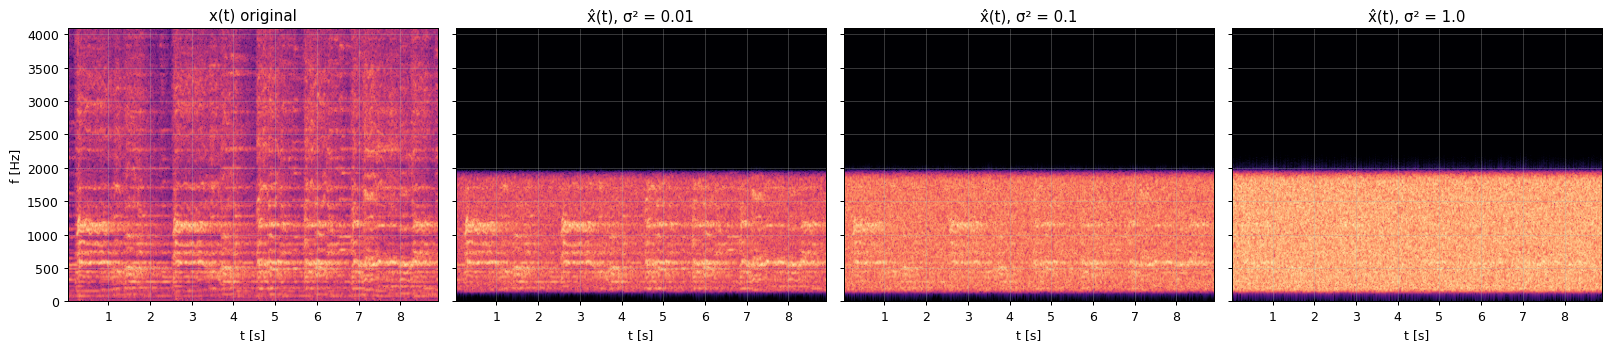


(c) Avaliação quantitativa (sistema FIR, sinais alinhados pelo atraso M/2)


,SNR entrada (dB),MSE entrada,SNR saída (dB),MSE saída,Ganho (dB),P ruído entrada,P ruído residual,P interf. residual,P distorção,SNR IIR (dB),MSE IIR
σ²,,,,,,,,,,,
0.01,4.35,0.0141,8.06,0.006,3.71,0.01,0.0041,2.8e-11,0.00196,6.05,0.0096
0.10,-4.33,0.1044,-0.46,0.0428,3.87,0.1002,0.0409,2.8e-11,0.00196,-0.97,0.0481
1.00,-14.18,1.0088,-10.28,0.4107,3.9,1.0046,0.4087,2.8e-11,0.00196,-10.51,0.4331


Potência das interferências na entrada: 4.06e-03

(d) Áudios — original, contaminados e recuperados
Original:


Contaminado, σ² = 0.01:


Recuperado (FIR), σ² = 0.01:


Contaminado, σ² = 0.1:


... (2 outputs left out)

Recuperado (FIR), σ² = 1.0:



(e) Quantização dos coeficientes (cada filtro quantizado separadamente; sistema = cascata)


,Coef. não nulos PA,Coef. não nulos PB,|H| 100 Hz (dB),|H| 2 kHz (dB),"Rejeição máx. > 2,1 kHz (dB)",Erro máx. 300–1700 Hz (dB),Estável,SNR saída (dB)
b,,,,,,,,
2,1/601,3/201,-8.5,-17.4,-9.4,14.38,sim (FIR),3.05
4,1/601,15/201,-1.6,-34.7,-16.1,3.02,sim (FIR),7.45
8,85/601,83/201,-22.9,-51.5,-29.0,0.71,sim (FIR),8.0
16,505/601,187/201,-82.0,-83.0,-74.3,0.01,sim (FIR),8.06


Original (sem quantização): |H| 100 Hz = -81.5 dB, |H| 2 kHz = -81.6 dB, SNR = 8.06 dB


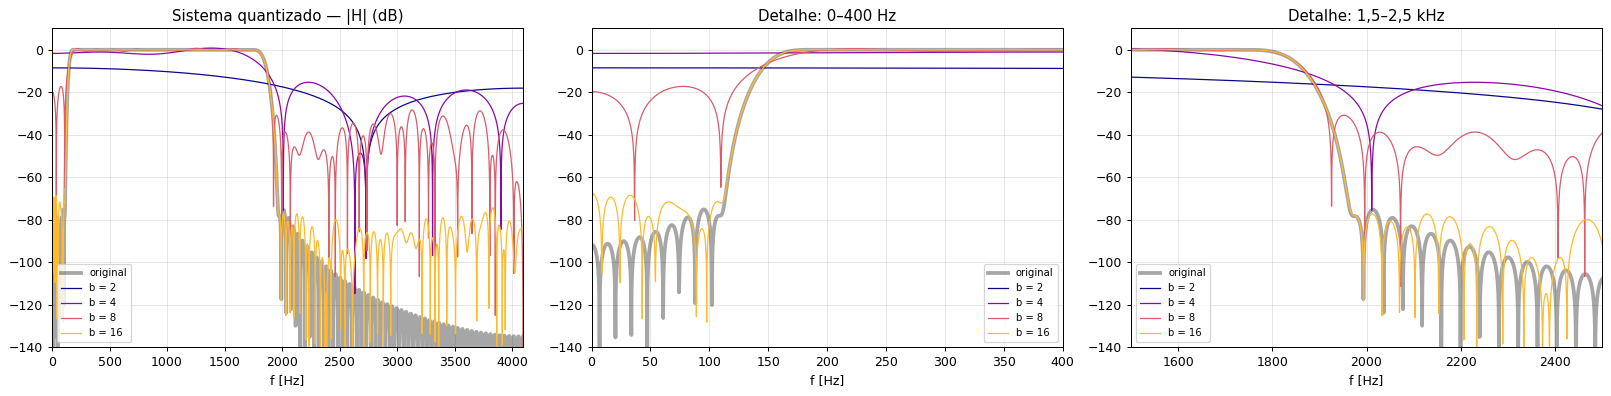

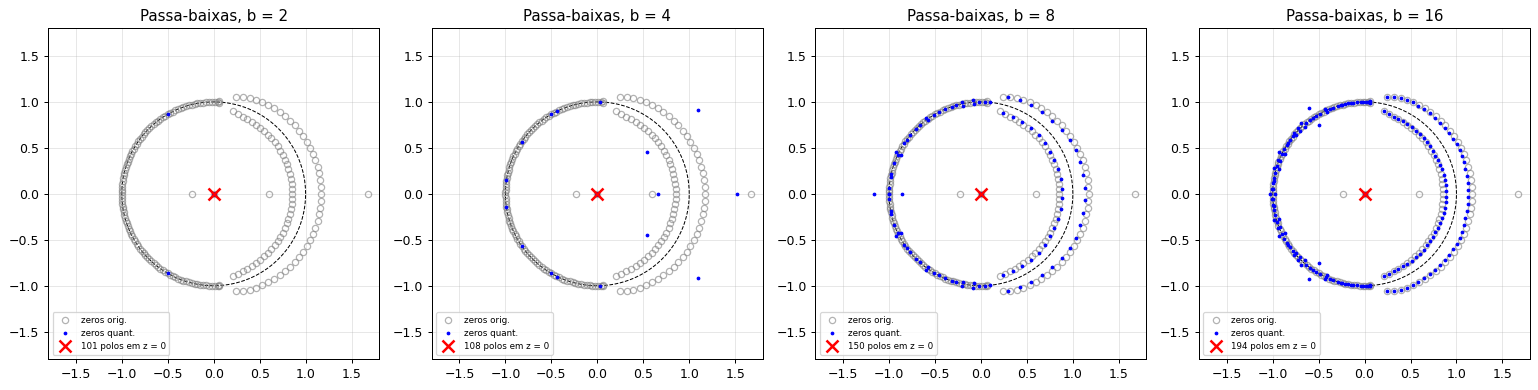

Recuperado com coeficientes de 4 bits (σ² = 0.01):


Recuperado com coeficientes de 8 bits (σ² = 0.01):


Recuperado com coeficientes de 16 bits (σ² = 0.01):


In [ ]:
# ============================================================
# Prática 8 — Questão 3
# Remoção de interferências e ruído do áudio handel.wav com filtros FIR
# projetados pelo método das janelas (projeto próprio, sem firwin)
# Comparação com o sistema IIR da prática anterior (notches + Butterworth)
# ============================================================
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams.update({'figure.dpi': 90, 'axes.grid': True, 'grid.alpha': 0.3})

url = 'https://raw.githubusercontent.com/LuisTT0903/Processamento-de-Sinais1/main/Aula_08/Audios_Usados/handel.wav'
if not os.path.exists('handel.wav'):
    urllib.request.urlretrieve(url, 'handel.wav')

fs, x = wavfile.read('handel.wav')
x = x.astype(float) / 32768.0
N = len(x)
t = np.arange(N) / fs
i1 = 0.05 * np.cos(200 * np.pi * t)      # 100 Hz
i2 = 0.075 * np.sin(4000 * np.pi * t)    # 2000 Hz
interf = i1 + i2
variancias = [1e-2, 1e-1, 1.0]
rng = np.random.default_rng(0)           # mesma semente da prática anterior (IIR)
ruidos = {s2: np.sqrt(s2) * rng.standard_normal(N) for s2 in variancias}
ys = {s2: x + interf + ruidos[s2] for s2 in variancias}

def pot(v):
    return np.mean(v ** 2)

def psd(v):
    f, P = signal.welch(v, fs=fs, nperseg=1024)
    return f, 10 * np.log10(P + 1e-20)

print(f'fs = {fs} Hz | N = {N} amostras | duração = {N / fs:.2f} s')
print(f'Potência de x: {pot(x):.5f} | interferência 100 Hz: {pot(i1):.5f} | interferência 2 kHz: {pot(i2):.5f}')
for s2 in variancias:
    print(f'sigma^2 = {s2:<5} SNR de entrada = {10 * np.log10(pot(x) / pot(ys[s2] - x)):6.2f} dB')

# ==================== Projeto FIR pelo método das janelas ====================
def janela(nome, M):
    n = np.arange(M + 1)
    if nome == 'Retangular':
        return np.ones(M + 1)
    if nome == 'Hann':
        return 0.5 - 0.5 * np.cos(2 * np.pi * n / M)
    if nome == 'Hamming':
        return 0.54 - 0.46 * np.cos(2 * np.pi * n / M)
    if nome == 'Blackman':
        return 0.42 - 0.5 * np.cos(2 * np.pi * n / M) + 0.08 * np.cos(4 * np.pi * n / M)
    raise ValueError(nome)

def hd_pb(M, fc):
    wc = 2 * np.pi * fc / fs
    k = np.arange(M + 1) - M / 2
    h = np.empty(M + 1)
    c = (k == 0)
    h[~c] = np.sin(wc * k[~c]) / (np.pi * k[~c])
    h[c] = wc / np.pi
    return h

def fir_pb(M, fc, jan='Blackman'):
    return hd_pb(M, fc) * janela(jan, M)

def fir_pa(M, fc, jan='Blackman'):
    d = np.zeros(M + 1); d[M // 2] = 1.0
    return (d - hd_pb(M, fc)) * janela(jan, M)

# Escolhas do projeto (M par -> filtro tipo I, atraso inteiro M/2):
#  - Passa-altas em 150 Hz: elimina a interferência de 100 Hz. Como 100 Hz fica a só 50 Hz do corte,
#    a meia-largura da transição da Blackman (~2,75 fs/M) precisa ser < 50 Hz -> M = 600.
#  - Passa-baixas em 1850 Hz: elimina a interferência de 2 kHz e o ruído acima da banda útil
#    (95% da energia da música está abaixo de ~1,7 kHz). Transição < 150 Hz -> M = 200.
JAN = 'Blackman'
M_PA, FC_PA = 600, 150
M_PB, FC_PB = 200, 1850
h_pa = fir_pa(M_PA, FC_PA, JAN)
h_pb = fir_pb(M_PB, FC_PB, JAN)
h_sis = np.convolve(h_pa, h_pb)                 # sistema completo (passa-faixas 150-1850 Hz)
ATRASO = (M_PA + M_PB) // 2                     # atraso de grupo exato do sistema (fase linear)
FILTROS = {f'Passa-altas {FC_PA} Hz (M = {M_PA})': h_pa,
           f'Passa-baixas {FC_PB} Hz (M = {M_PB})': h_pb,
           f'Sistema completo (M = {M_PA + M_PB})': h_sis}
print(f'\nAtraso do sistema: {ATRASO} amostras = {1000 * ATRASO / fs:.1f} ms (constante em todas as frequências)')

def resp(h, n=16384):
    w, H = signal.freqz(h, 1, worN=n, fs=fs)
    return w, H

def ganho_db(h, f0):
    n = np.arange(len(h))
    return 20 * np.log10(abs(np.sum(h * np.exp(-2j * np.pi * f0 / fs * n))) + 1e-15)

def zeros_fir(h):
    c = np.array(h, float)
    c[np.abs(c) < 1e-14 * np.max(np.abs(c))] = 0
    ini = np.argmax(c != 0); fim = len(c) - np.argmax(c[::-1] != 0)
    z = np.roots(c[ini:fim]) if fim - ini > 1 else np.array([])
    return np.r_[z, np.zeros(len(c) - fim)], len(c) - 1 - ini   # zeros, número de polos em z = 0

# ==================== (a) Filtros projetados ====================
print('\n(a) Filtros projetados — ganhos em frequências de interesse')
linhas = {}
for nome, h in FILTROS.items():
    linhas[nome] = {f'{f0} Hz (dB)': round(ganho_db(h, f0), 1) for f0 in [100, 150, 300, 1000, 1850, 2000, 3000]}
display(pd.DataFrame(linhas).T)

fig, axs = plt.subplots(len(FILTROS), 3, figsize=(16, 4 * len(FILTROS)), gridspec_kw={'width_ratios': [1.2, 1.6, 1]})
th = np.linspace(0, 2 * np.pi, 400)
for i, (nome, h) in enumerate(FILTROS.items()):
    axs[i, 0].plot(np.arange(len(h)), h, lw=0.8)
    axs[i, 0].set_title(f'{nome}: h[n]'); axs[i, 0].set_xlabel('n')
    w, H = resp(h)
    axs[i, 1].plot(w, 20 * np.log10(np.abs(H) + 1e-12), lw=1)
    for fi in [100, 2000]:
        axs[i, 1].axvline(fi, color='r', ls='--', lw=0.8)
    axs[i, 1].set_ylim(-140, 10); axs[i, 1].set_xlim(0, fs / 2)
    axs[i, 1].set_title(f'{nome}: |H(f)| (dB)'); axs[i, 1].set_xlabel('f [Hz]')
    z, npol = zeros_fir(h)
    axs[i, 2].plot(np.cos(th), np.sin(th), 'k--', lw=0.8)
    axs[i, 2].plot(z.real, z.imag, 'o', mfc='none', mec='C0', ms=3)
    axs[i, 2].plot(0, 0, 'x', color='C3', ms=9, mew=2)
    axs[i, 2].annotate(f'{npol} polos', (0.05, 0.08), color='C3', fontsize=8)
    lim = 1.6
    axs[i, 2].set_xlim(-lim, lim); axs[i, 2].set_ylim(-lim, lim); axs[i, 2].set_aspect('equal')
    fora = np.sum(np.abs(z) > lim)
    axs[i, 2].set_title(f'{nome}: polos e zeros' + (f' ({fora} fora)' if fora else ''), fontsize=9)
fig.tight_layout(); plt.show()

# Detalhe das bordas e fase linear
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
w, H = resp(h_sis, 65536)
HdB = 20 * np.log10(np.abs(H) + 1e-12)
ax[0].plot(w, HdB); ax[0].set_xlim(0, 400); ax[0].set_ylim(-120, 5); ax[0].axvline(100, color='r', ls='--')
ax[0].set_title('Sistema: detalhe em baixas frequências'); ax[0].set_xlabel('f [Hz]')
ax[1].plot(w, HdB); ax[1].set_xlim(1500, 2500); ax[1].set_ylim(-120, 5); ax[1].axvline(2000, color='r', ls='--')
ax[1].set_title('Sistema: detalhe perto de 2 kHz'); ax[1].set_xlabel('f [Hz]')
fase = np.unwrap(np.angle(H)); banda = (w > 300) & (w < 1700)
tau = -np.diff(fase) / np.diff(2 * np.pi * w / fs)
ax[2].plot(w[1:][banda[1:]], tau[banda[1:]]); ax[2].set_ylim(ATRASO - 5, ATRASO + 5)
ax[2].set_title(f'Atraso de grupo na banda de passagem (= {ATRASO} amostras)'); ax[2].set_xlabel('f [Hz]')
fig.tight_layout(); plt.show()

# Escolha da janela e da ordem: SNR de saída para σ² = 0,01
def filtra(h, v):
    """Filtra e compensa o atraso M/2 (fase linear -> alinhamento exato)."""
    D = (len(h) - 1) // 2
    return signal.fftconvolve(v, h)[D:D + len(v)]

def sistema(jan, m_pa, m_pb, fc_pa=FC_PA, fc_pb=FC_PB):
    return np.convolve(fir_pa(m_pa, fc_pa, jan), fir_pb(m_pb, fc_pb, jan))

print('\nEscolha da janela (σ² = 0,01, M_PA = 600, M_PB = 200):')
tab = {}
for jan in ['Retangular', 'Hann', 'Hamming', 'Blackman']:
    h = sistema(jan, M_PA, M_PB)
    tab[jan] = {'|H| 100 Hz (dB)': round(ganho_db(h, 100), 1), '|H| 2 kHz (dB)': round(ganho_db(h, 2000), 1),
                'Interf. residual (dB rel. entrada)': round(10 * np.log10(pot(filtra(h, interf)[2000:-2000]) / pot(interf)), 1),
                'SNR saída (dB)': round(10 * np.log10(pot(x) / pot(filtra(h, ys[1e-2]) - x)), 2)}
display(pd.DataFrame(tab).T)

print('Escolha da ordem do passa-altas (Blackman, σ² = 0,01):')
tab = {}
for m in [100, 200, 400, 600, 800, 1200]:
    h = sistema('Blackman', m, M_PB)
    tab[m] = {'|H| 100 Hz (dB)': round(ganho_db(h, 100), 1),
              'SNR saída (dB)': round(10 * np.log10(pot(x) / pot(filtra(h, ys[1e-2]) - x)), 2),
              'Atraso (ms)': round(1000 * (m + M_PB) / 2 / fs, 1)}
display(pd.DataFrame(tab).T.rename_axis('M_PA'))

# ==================== (b) Filtragem: tempo e frequência ====================
xr = {s2: filtra(h_sis, ys[s2]) for s2 in variancias}
n0, n1 = int(2.0 * fs), int(2.05 * fs)
fig, ax = plt.subplots(len(variancias), 2, figsize=(15, 10))
for k, s2 in enumerate(variancias):
    ax[k, 0].plot(t[n0:n1] * 1000, ys[s2][n0:n1], lw=0.6, alpha=0.6, label='y(t)')
    ax[k, 0].plot(t[n0:n1] * 1000, xr[s2][n0:n1], lw=1.3, label='x̂(t)')
    ax[k, 0].plot(t[n0:n1] * 1000, x[n0:n1], 'k', lw=1.3, label='x(t)')
    ax[k, 0].set_title(f'Tempo (50 ms) — σ² = {s2}'); ax[k, 0].set_xlabel('t [ms]'); ax[k, 0].legend(loc='upper right', fontsize=8)
    for v, nome, cor in [(ys[s2], 'y(t)', 'C0'), (xr[s2], 'x̂(t)', 'C1'), (x, 'x(t)', 'k')]:
        fv, Pv = psd(v)
        ax[k, 1].plot(fv, Pv, lw=0.9, label=nome, color=cor)
    ax[k, 1].set_title(f'Densidade espectral — σ² = {s2}'); ax[k, 1].set_xlabel('f [Hz]'); ax[k, 1].set_ylabel('dB/Hz')
    ax[k, 1].legend(loc='upper right', fontsize=8)
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for a_, (nome, v) in zip(ax, [('x(t) original', x)] + [(f'x̂(t), σ² = {s2}', xr[s2]) for s2 in variancias]):
    a_.specgram(v, NFFT=512, Fs=fs, noverlap=384, cmap='magma', vmin=-120, vmax=-20)
    a_.set_title(nome); a_.set_xlabel('t [s]')
ax[0].set_ylabel('f [Hz]')
fig.tight_layout(); plt.show()

# ==================== (c) Métricas ====================
print('\n(c) Avaliação quantitativa (sistema FIR, sinais alinhados pelo atraso M/2)')
IIR = {1e-2: (6.05, 0.0096), 1e-1: (-0.97, 0.0481), 1.0: (-10.51, 0.4331)}   # resultados da prática anterior
borda = 2000
tab = {}
for s2 in variancias:
    snr_in = 10 * np.log10(pot(x) / pot(ys[s2] - x))
    mse = pot(xr[s2] - x)
    snr_out = 10 * np.log10(pot(x) / mse)
    tab[s2] = {'SNR entrada (dB)': round(snr_in, 2), 'MSE entrada': round(pot(ys[s2] - x), 4),
               'SNR saída (dB)': round(snr_out, 2), 'MSE saída': round(mse, 4), 'Ganho (dB)': round(snr_out - snr_in, 2),
               'P ruído entrada': round(pot(ruidos[s2]), 4), 'P ruído residual': round(pot(filtra(h_sis, ruidos[s2])), 4),
               'P interf. residual': f'{pot(filtra(h_sis, interf)[borda:-borda]):.1e}',
               'P distorção': round(pot(filtra(h_sis, x) - x), 5),
               'SNR IIR (dB)': IIR[s2][0], 'MSE IIR': IIR[s2][1]}
display(pd.DataFrame(tab).T.rename_axis('σ²'))
print(f'Potência das interferências na entrada: {pot(interf):.2e}')

# ==================== (d) Áudios ====================
print('\n(d) Áudios — original, contaminados e recuperados')
print('Original:'); display(Audio(x, rate=fs))
for s2 in variancias:
    print(f'Contaminado, σ² = {s2}:'); display(Audio(ys[s2], rate=fs))
    print(f'Recuperado (FIR), σ² = {s2}:'); display(Audio(xr[s2], rate=fs))

# ==================== (e) Quantização dos coeficientes ====================
def quantiza(c, b):
    """Ponto fixo com b bits (1 de sinal); a parte inteira é escolhida pelo maior coeficiente."""
    c = np.asarray(c, float)
    m = np.max(np.abs(c))
    inteiros = int(np.floor(np.log2(m))) + 1
    passo = 2.0 ** (inteiros - (b - 1))
    return np.clip(np.round(c / passo) * passo, -2.0 ** inteiros, 2.0 ** inteiros - passo)

bits = [2, 4, 8, 16]
s2_ref = 1e-2
print('\n(e) Quantização dos coeficientes (cada filtro quantizado separadamente; sistema = cascata)')
res_q = {}
tab = {}
for b in bits:
    qa, qb = quantiza(h_pa, b), quantiza(h_pb, b)
    hq = np.convolve(qa, qb)
    res_q[b] = (qa, qb, hq)
    sq = filtra(hq, ys[s2_ref])
    w, Hq = resp(hq)
    banda = (w > 300) & (w < 1700)
    _, H0 = resp(h_sis)
    tab[b] = {'Coef. não nulos PA': f'{np.count_nonzero(qa)}/{len(qa)}', 'Coef. não nulos PB': f'{np.count_nonzero(qb)}/{len(qb)}',
              '|H| 100 Hz (dB)': round(ganho_db(hq, 100), 1), '|H| 2 kHz (dB)': round(ganho_db(hq, 2000), 1),
              'Rejeição máx. > 2,1 kHz (dB)': round(20 * np.log10(np.max(np.abs(Hq[w > 2100])) + 1e-15) - 20 * np.log10(np.max(np.abs(Hq[banda])) + 1e-15), 1),
              'Erro máx. 300–1700 Hz (dB)': round(np.max(np.abs(20 * np.log10(np.abs(Hq[banda]) + 1e-12) - 20 * np.log10(np.abs(H0[banda])))), 2),
              'Estável': 'sim (FIR)', 'SNR saída (dB)': round(10 * np.log10(pot(x) / pot(sq - x)), 2)}
display(pd.DataFrame(tab).T.rename_axis('b'))
print(f'Original (sem quantização): |H| 100 Hz = {ganho_db(h_sis, 100):.1f} dB, |H| 2 kHz = {ganho_db(h_sis, 2000):.1f} dB, '
      f'SNR = {10 * np.log10(pot(x) / pot(xr[s2_ref] - x)):.2f} dB')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
w0, H0 = resp(h_sis)
for a_ in ax:
    a_.plot(w0, 20 * np.log10(np.abs(H0) + 1e-12), 'k', lw=3, alpha=0.35, label='original')
for b, c in zip(bits, plt.cm.plasma(np.linspace(0, 0.85, len(bits)))):
    w, Hq = resp(res_q[b][2])
    for a_ in ax:
        a_.plot(w, 20 * np.log10(np.abs(Hq) + 1e-12), color=c, lw=1, label=f'b = {b}')
ax[0].set_xlim(0, fs / 2); ax[0].set_ylim(-140, 10); ax[0].set_title('Sistema quantizado — |H| (dB)')
ax[1].set_xlim(0, 400); ax[1].set_ylim(-140, 10); ax[1].set_title('Detalhe: 0–400 Hz')
ax[2].set_xlim(1500, 2500); ax[2].set_ylim(-140, 10); ax[2].set_title('Detalhe: 1,5–2,5 kHz')
for a_ in ax:
    a_.set_xlabel('f [Hz]'); a_.legend(fontsize=8)
fig.tight_layout(); plt.show()

# Polos e zeros do passa-baixas (M = 200) quantizado
z0, _ = zeros_fir(h_pb)
fig, ax = plt.subplots(1, len(bits), figsize=(4.3 * len(bits), 4.4))
for a_, b in zip(ax, bits):
    zq, npol = zeros_fir(res_q[b][1])
    a_.plot(np.cos(th), np.sin(th), 'k--', lw=0.8)
    a_.plot(z0.real, z0.imag, 'o', mfc='none', mec='gray', ms=5, alpha=0.6, label='zeros orig.')
    a_.plot(zq.real, zq.imag, 'b.', ms=4, label='zeros quant.')
    a_.plot(0, 0, 'rx', ms=9, mew=2, label=f'{npol} polos em z = 0')
    a_.set_xlim(-1.8, 1.8); a_.set_ylim(-1.8, 1.8); a_.set_aspect('equal')
    a_.set_title(f'Passa-baixas, b = {b}'); a_.legend(fontsize=7, loc='lower left')
fig.tight_layout(); plt.show()

for b in [4, 8, 16]:
    print(f'Recuperado com coeficientes de {b} bits (σ² = {s2_ref}):')
    display(Audio(filtra(res_q[b][2], ys[s2_ref]), rate=fs))

## Comentários sobre os resultados

**(a) Filtros projetados.** O sistema é uma cascata de dois filtros FIR projetados pelo método das janelas (janela de Blackman), o que equivale a um passa-faixas de 150 a 1850 Hz:

- **Passa-altas, $f_c = 150$ Hz, $M = 600$**, para remover a interferência de 100 Hz. Como 100 Hz fica a apenas 50 Hz do corte, a meia-largura da transição da Blackman ($\approx 2{,}75\,f_s/M$) precisa ser menor que 50 Hz, o que exige uma ordem alta.
- **Passa-baixas, $f_c = 1850$ Hz, $M = 200$**, para remover a interferência de 2 kHz e o ruído acima da banda útil (95% da energia da música fica abaixo de ~1,7 kHz).

O sistema atenua **−81,5 dB em 100 Hz** e **−81,6 dB em 2 kHz**, com ganho de 0 dB entre 300 e 1700 Hz e −6 dB exatamente nas frequências de corte. Os únicos polos estão em z = 0 (600, 200 e 800 polos, respectivamente), então os filtros são sempre estáveis. Os zeros aparecem em pares recíprocos ($z_0$, $1/z_0^*$), pela simetria de $h[n]$. Os zeros sobre a circunferência unitária ficam nas bandas de rejeição (abaixo de ~100 Hz e acima de ~1950 Hz). O atraso de grupo é constante e igual a 400 amostras (48,8 ms), o que confirma a fase linear.

Na escolha da janela, com as mesmas ordens, a retangular só atinge −37 dB nas interferências (Gibbs), a Hamming −61 dB, a Hann −71 dB e a Blackman −82 dB. A SNR praticamente não muda (8,00 a 8,06 dB), porque a potência das interferências é pequena perto da do ruído, mas o zumbido residual é audível com as janelas piores. Na escolha da ordem do passa-altas, com $M = 100$ ou $200$ a transição é larga demais e 100 Hz só cai 12 a 21 dB. Com $M = 600$ chega a −81 dB, e ordens maiores só aumentam o atraso.

**Comparação com a prática anterior (IIR).** O sistema IIR tinha ordem total 10 (dois notches com $r = 0{,}99$ e um Butterworth de 6ª ordem), enquanto o FIR precisa de ordem 800 para seletividade equivalente. Isso dá cerca de 400 multiplicações por amostra (aproveitando a simetria), contra cerca de 25 no IIR. O atraso também é maior: 48,8 ms contra cerca de 0,4 ms. Em troca, o FIR tem fase exatamente linear, é sempre estável e não tem transitório longo de notch.

**(b) Filtragem — tempo e frequência.** No espectro, as raias de 100 Hz e 2 kHz desaparecem por completo, e o ruído acima de ~1,9 kHz cai de 70 dB (logo após o corte) a mais de 120 dB (perto de 4 kHz), ficando muito abaixo do próprio espectro da música. Entre 150 e 1850 Hz o ruído permanece no mesmo nível, porque ocupa a mesma faixa da música e não pode ser separado por filtragem linear. No tempo, com σ² = 0,01 o sinal recuperado (alinhado pelo atraso M/2) acompanha bem x(t). Com σ² = 0,1 e 1 a forma de onda continua dominada pelo ruído dentro da banda. Em relação ao IIR, a diferença visível é a fase: o FIR não distorce a forma de onda, apenas a atrasa, então o alinhamento com x(t) é exato.

**(c) Métricas.**

| σ² | SNR entrada | SNR saída FIR | SNR saída IIR | MSE FIR | MSE IIR |
|---|---|---|---|---|---|
| 0,01 | 4,35 dB | **8,06 dB** | 6,05 dB | 0,0060 | 0,0096 |
| 0,1 | −4,33 dB | **−0,46 dB** | −0,97 dB | 0,0428 | 0,0481 |
| 1 | −14,18 dB | **−10,28 dB** | −10,51 dB | 0,4107 | 0,4331 |

O ganho de SNR do FIR é de 3,7 a 3,9 dB, praticamente constante. O ruído residual é ~41% do ruído de entrada, ou seja, a fração do ruído branco que fica dentro de 150 a 1850 Hz. As interferências residuais caem de 4,1·10⁻³ para ~10⁻¹¹ de potência. O FIR supera o IIR em todos os casos, e a diferença é maior com ruído baixo (+2 dB para σ² = 0,01). Isso acontece porque, nesse caso, o erro é dominado pela distorção do próprio filtro: a potência de distorção do FIR é 0,0020, contra 0,0053 do IIR, já que a fase não linear do IIR deforma a música. O valor do FIR coincide com o que o IIR atingia só com filtragem de fase zero (8,25 dB). Com ruído alto, os dois ficam parecidos, porque o limite passa a ser o ruído dentro da banda.

**(d) Avaliação subjetiva.** Pelos espectros e espectrogramas, nos áudios recuperados o zumbido grave de 100 Hz e o apito de 2 kHz devem desaparecer por completo, já que ficam 80 dB abaixo, contra a eliminação apenas em regime permanente do notch IIR. O chiado fica mais grave e abafado, porque só o ruído entre 150 e 1850 Hz sobra. Com σ² = 0,01 a música deve ser bem inteligível. Com 0,1 ela é reconhecível sob um chiado forte, e com 1 continua quase mascarada, como no IIR. A perda de agudos acima de 1,85 kHz e de graves abaixo de 150 Hz deixa o timbre levemente "de rádio". Não há ecos nem distorções de fase, porque o atraso é igual em todas as frequências. Ao comparar com o IIR, a diferença perceptível tende a ser pequena: o FIR soa um pouco mais fiel com ruído baixo e corta um pouco mais de graves por causa do passa-altas em 150 Hz.

**(e) Quantização dos coeficientes.** Cada filtro foi quantizado em ponto fixo com b bits.

- **16 bits:** o sistema é praticamente idêntico ao original: −82 dB nas interferências, erro de 0,01 dB na banda e SNR de 8,06 dB.
- **8 bits:** a resposta em frequência se mantém na banda (erro de 0,7 dB), mas a rejeição piora para −23 dB em 100 Hz e −52 dB em 2 kHz. A SNR ainda é de 8,0 dB.
- **4 bits:** o passa-altas colapsa. Seu maior coeficiente é o central (~0,96), e todos os outros são menores que ~0,037, então com passo de 0,125 eles são arredondados para zero. Sobra só um atraso puro, a interferência de 100 Hz passa (−1,6 dB) e volta o zumbido. O passa-baixas fica com só 15 coeficientes não nulos e rejeição de apenas −16 dB.
- **2 bits:** o sistema não filtra mais nada útil (SNR de 3,05 dB, abaixo da própria entrada).

No diagrama de polos e zeros, os polos continuam todos em z = 0 para qualquer b, então **o FIR nunca fica instável**. A quantização só desloca os zeros. Com poucos bits, eles saem da circunferência unitária na banda de rejeição, o que reduz a atenuação. Como os coeficientes continuam simétricos, os zeros continuam em pares recíprocos e a **fase linear é preservada mesmo com coeficientes quantizados**.

Em comparação com a prática anterior: no IIR, a forma direta era instável com 2, 4 e 8 bits, e a cascata era marginal com 2 e 4 bits. Com 8 bits, o notch de 100 Hz se desfazia e a SNR caía para 1,9 dB. No FIR, a quantização nunca causa instabilidade nem ressonâncias, e com 8 bits o desempenho em SNR é quase o original. A desvantagem do FIR é que filtros longos com coeficientes pequenos, como o passa-altas de ordem 600, precisam de mais bits para manter a rejeição.

**Conclusão.** O FIR obtém SNR igual ou melhor que o IIR, elimina as interferências por completo e tem fase linear, estabilidade garantida e boa robustez à quantização. O custo é uma ordem cerca de 80 vezes maior, com mais operações por amostra e um atraso de ~49 ms. Para processamento offline de áudio, esse custo é aceitável. Em sistemas de tempo real com pouca capacidade de processamento, o IIR em cascata continua sendo a opção mais econômica.